<div style="background:#0B2545;color:white;padding:18px 22px;border-radius:8px">
<div style="font-size:12px;letter-spacing:2px;opacity:.8">DATABANK ACADEMY · PROGRAMA EJECUTIVO EN GESTIÓN INTEGRAL DEL RIESGO DE CRÉDITO MINORISTA</div>
<div style="font-size:24px;font-weight:700;margin-top:6px">Módulo 4 · Sesión 3: Gradient boosting (Friedman, 2001)</div>
<div style="font-size:14px;margin-top:4px;opacity:.9">Laboratorio: descenso de gradiente en el espacio de funciones, L2_TreeBoost desde cero, paso de Newton por hoja, shrinkage, submuestreo e interpretación</div>
</div>

## Objetivos de la sesión (2 horas)

Derivar e implementar el **gradient boosting** de Friedman, *"Greedy Function Approximation: A Gradient Boosting Machine"*, *The Annals of Statistics* 29(5), 2001:

1. Estimación de funciones como **optimización numérica en el espacio de funciones** (secciones 1-3).
2. El algoritmo genérico **Gradient_Boost** (algoritmo 1): pseudo-residuos y búsqueda lineal.
3. **TreeBoost**: árboles de regresión con un valor óptimo por hoja (sección 4.3).
4. **L2_TreeBoost** para clasificación binaria (algoritmo 5): pérdida binomial, paso de Newton en cada hoja.
5. **Regularización**: shrinkage (sección 5) y submuestreo estocástico (Friedman, 2002).
6. **Interpretación**: influencia relativa y dependencia parcial (sección 8).

Implementamos L2_TreeBoost **desde cero** y lo verificamos contra `scikit-learn`.

| Bloque | Tiempo | Contenido |
|---|---|---|
| 1 | 25 min | Descenso de gradiente en el espacio de funciones |
| 2 | 15 min | Funciones de pérdida: LS, LAD, Huber, binomial |
| 3 | 30 min | L2_TreeBoost: derivación e implementación |
| 4 | 25 min | Shrinkage, número de iteraciones y submuestreo |
| 5 | 15 min | Influencia relativa y dependencia parcial |
| 6 | 10 min | Ejercicios |

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .3, "font.size": 11})
AZUL, ROJO, VERDE, GRIS, ORO = "#0B2545", "#C8102E", "#2E8B57", "#8D99AE", "#E0A100"
DATA = Path("../datos")

import warnings; warnings.filterwarnings("ignore")
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.inspection import partial_dependence
from sklearn.metrics import roc_auc_score, log_loss
app = pd.read_csv(DATA / "hc_application_sintetico.csv").drop_duplicates()
app["EDAD"] = -app.DAYS_BIRTH / 365.25
app["RCI"] = app.AMT_ANNUITY / (app.AMT_INCOME_TOTAL / 12)
app["EXT1"] = app.EXT_SOURCE_1.fillna(-1); app["EXT2"] = app.EXT_SOURCE_2.fillna(-1); app["EXT3"] = app.EXT_SOURCE_3.fillna(-1)
app["ANTIG"] = np.where(app.DAYS_EMPLOYED == 365243, -1, -app.DAYS_EMPLOYED / 365.25)
FEATS = ["EXT1", "EXT2", "EXT3", "EDAD", "RCI", "ANTIG", "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_REQ_CREDIT_BUREAU_YEAR", "REGION_RATING_CLIENT"]
dev = app[app.FECHA_SOLICITUD < "2025-01"]; oot = app[app.FECHA_SOLICITUD >= "2025-01"]
X, y, Xo, yo = dev[FEATS].values, dev.TARGET.values, oot[FEATS].values, oot.TARGET.values
print(X.shape, Xo.shape)

(45092, 10) (14908, 10)


## 1. Optimización en el espacio de funciones (Friedman, secciones 1-3)
Buscamos la función que minimiza la pérdida esperada: $F^*(x) = \arg\min_F E_{y,x}\,L(y, F(x))$.

**En el espacio de parámetros** (sección 2), el descenso más pronunciado actualiza $P_m = P_{m-1} - \rho_m g_m$, con $g_m$ el gradiente. Friedman aplica la misma idea **a la función misma**: tratar $F(x)$ en cada punto $x$ como un "parámetro". El gradiente en el espacio de funciones es
$$g_m(x) = \left[\frac{\partial E_y[L(y, F(x)) \mid x]}{\partial F(x)}\right]_{F = F_{m-1}}$$
Con datos finitos, ese gradiente solo se conoce en los puntos de entrenamiento: los **pseudo-residuos** $\tilde{y}_{im} = -\left[\partial L(y_i, F(x_i)) / \partial F(x_i)\right]_{F = F_{m-1}}$. Para generalizar a cualquier $x$, se ajusta un **aprendiz base** $h(x; a)$ que aproxime $-g_m$ por mínimos cuadrados (ecuación 11), y luego se busca el tamaño del paso (ecuación 12).

### Algoritmo 1: Gradient_Boost
1. $F_0(x) = \arg\min_\rho \sum_{i} L(y_i, \rho)$
2. Para $m = 1, \dots, M$:
   - $\tilde{y}_{i} = -\left[\partial L(y_i, F(x_i)) / \partial F(x_i)\right]_{F = F_{m-1}}$
   - $a_m = \arg\min_{a, \beta} \sum_i [\tilde{y}_i - \beta h(x_i; a)]^2$
   - $\rho_m = \arg\min_\rho \sum_i L(y_i, F_{m-1}(x_i) + \rho\, h(x_i; a_m))$
   - $F_m(x) = F_{m-1}(x) + \rho_m h(x; a_m)$

## 2. Funciones de pérdida
| Algoritmo (Friedman) | Pérdida $L(y, F)$ | Pseudo-residuo $\tilde{y}$ | Valor de la hoja |
|---|---|---|---|
| LS_Boost | $\tfrac{1}{2}(y - F)^2$ | $y - F$ | media de los residuos |
| LAD_TreeBoost | $|y - F|$ | $\text{sign}(y - F)$ | mediana de los residuos |
| M_TreeBoost | Huber | residuo truncado | M-estimador |
| **L2_TreeBoost** | $\log(1 + e^{-2yF})$, $y \in \{-1, 1\}$ | $2y / (1 + e^{2yF})$ | un paso de Newton |

## 3. L2_TreeBoost (sección 4.5, algoritmo 5)
Con $y \in \{-1, 1\}$ y la deviance binomial $L(y, F) = \log(1 + e^{-2yF})$, el minimizador poblacional es $F^*(x) = \tfrac{1}{2}\log\frac{P(y=1|x)}{P(y=-1|x)}$ (**la mitad** del log-odds). Por eso:
- $F_0 = \tfrac{1}{2}\log\frac{1+\bar y}{1-\bar y}$
- $\tilde{y}_i = \dfrac{2y_i}{1 + \exp(2y_iF_{m-1}(x_i))}$
- Con **TreeBoost** (sección 4.3), cada hoja $R_{jm}$ recibe su propio valor óptimo $\gamma_{jm} = \arg\min_\gamma \sum_{x_i \in R_{jm}} L(y_i, F_{m-1}(x_i) + \gamma)$. No tiene forma cerrada; Friedman usa **un paso de Newton-Raphson** (ecuación 23):
$$\gamma_{jm} = \frac{\sum_{x_i \in R_{jm}} \tilde{y}_i}{\sum_{x_i \in R_{jm}} |\tilde{y}_i|\,(2 - |\tilde{y}_i|)}$$
- Probabilidad: $p_+(x) = 1 / (1 + e^{-2F_M(x)})$.

**Derivación del denominador:** $\partial^2 L/\partial F^2 = 4p(1-p)$ y, con $|\tilde{y}| = 2(1-p_{y})$, se cumple $|\tilde{y}|(2 - |\tilde{y}|) = 4p(1-p)$. El numerador es menos el gradiente. Es exactamente el paso de Newton del Módulo 3 aplicado hoja por hoja.

In [2]:
def l2_treeboost(X, y01, M=100, J=8, nu=0.1, subsample=1.0, X_eval=None, seed=0):
    """L2_TreeBoost de Friedman (2001), algoritmo 5, con y en {-1, 1}."""
    rng = np.random.default_rng(seed)
    yy = 2 * y01 - 1
    ybar = yy.mean()
    F0 = 0.5 * np.log((1 + ybar) / (1 - ybar))
    F = np.full(len(yy), F0); Fe = None if X_eval is None else np.full(len(X_eval), F0)
    arboles, hist = [], []
    for m in range(M):
        ytil = 2 * yy / (1 + np.exp(2 * yy * F))                               # pseudo-residuos
        idx = np.arange(len(yy)) if subsample == 1.0 else rng.choice(len(yy), int(subsample * len(yy)), replace=False)
        arbol = DecisionTreeRegressor(max_leaf_nodes=J, criterion="friedman_mse", random_state=seed).fit(X[idx], ytil[idx])
        hojas = arbol.apply(X[idx])
        gam = {}
        for h in np.unique(hojas):                                             # un paso de Newton por hoja
            r = ytil[idx][hojas == h]
            gam[h] = r.sum() / np.sum(np.abs(r) * (2 - np.abs(r)))
        F += nu * np.vectorize(gam.get)(arbol.apply(X))
        if X_eval is not None:
            Fe += nu * np.vectorize(gam.get)(arbol.apply(X_eval)); hist.append(Fe.copy())
        arboles.append((arbol, gam))
    return F0, arboles, hist

def proba(F): return 1 / (1 + np.exp(-2 * F))

import time; t0 = time.time()
F0, arboles, hist = l2_treeboost(X, y, M=150, J=8, nu=0.1, X_eval=Xo)
p_own = proba(hist[-1])
print(f"L2_TreeBoost desde cero (150 árboles de 8 hojas) en {time.time() - t0:.0f} s | F0 = {F0:.4f} = ½·log-odds = {0.5 * np.log(y.mean() / (1 - y.mean())):.4f}")
sk = GradientBoostingClassifier(n_estimators=150, max_leaf_nodes=8, learning_rate=0.1, max_depth=None, random_state=0).fit(X, y)
p_sk = sk.predict_proba(Xo)[:, 1]
print(f"AUC fuera de tiempo: propio {roc_auc_score(yo, p_own):.4f} | scikit-learn {roc_auc_score(yo, p_sk):.4f}")
print(f"Diferencia media absoluta de PD: {np.abs(p_own - p_sk).mean():.4f} | correlación: {np.corrcoef(p_own, p_sk)[0, 1]:.4f}")
arbol_sk = sk.estimators_[0, 0].tree_; arbol_pr = arboles[0][0].tree_
print("Primer árbol, primeras particiones (variable, umbral):")
print("  propio:      ", [(FEATS[f], round(t, 4)) for f, t in zip(arbol_pr.feature[:3], arbol_pr.threshold[:3])])
print("  scikit-learn:", [(FEATS[f], round(t, 4)) for f, t in zip(arbol_sk.feature[:3], arbol_sk.threshold[:3])])

L2_TreeBoost desde cero (150 árboles de 8 hojas) en 22 s | F0 = -1.1763 = ½·log-odds = -1.1763


AUC fuera de tiempo: propio 0.7515 | scikit-learn 0.7515
Diferencia media absoluta de PD: 0.0001 | correlación: 0.9973
Primer árbol, primeras particiones (variable, umbral):
  propio:       [('EXT2', np.float64(0.3718)), ('EXT2', np.float64(0.2345)), ('EXT2', np.float64(0.5915))]
  scikit-learn: [('EXT2', np.float64(0.3718)), ('EXT2', np.float64(0.2345)), ('EXT2', np.float64(0.5915))]


**Verificación:** la implementación de 25 líneas reproduce a `GradientBoostingClassifier`, que parametriza con $y \in \{0,1\}$ y $F$ igual al log-odds completo; las diferencias de escala se compensan exactamente. Las primeras particiones son idénticas y el AUC coincide. Las diferencias individuales aparecen porque, en niveles profundos, hay **casi-empates** entre particiones: un desempate distinto cambia un árbol y el cambio se propaga a los siguientes. Es la misma inestabilidad de los árboles vista en la sesión 2.

### Un paso del algoritmo, en detalle

In [3]:
yy = 2 * y - 1
F = np.full(len(yy), F0)
ytil = 2 * yy / (1 + np.exp(2 * yy * F))
print(f"Iteración 1: pseudo-residuos de los buenos = {ytil[y == 0][0]:.4f}, de los malos = {ytil[y == 1][0]:.4f}")
arbol1, gam1 = arboles[0]
hojas = arbol1.apply(X)
t = pd.DataFrame({"hoja": hojas, "y": y, "ytil": ytil}).groupby("hoja").agg(n=("y", "size"), tasa_malos=("y", "mean"), suma_ytil=("ytil", "sum"),
                                                                           denom=("ytil", lambda r: np.sum(np.abs(r) * (2 - np.abs(r)))))
t["gamma (Newton)"] = t.suma_ytil / t.denom; t["gamma árbol"] = [gam1[h] for h in t.index]
t["PD tras el paso (ν = 1)"] = proba(F0 + t["gamma (Newton)"])
t.style.format({"tasa_malos": "{:.2%}", "suma_ytil": "{:.1f}", "denom": "{:.1f}", "gamma (Newton)": "{:+.4f}", "gamma árbol": "{:+.4f}", "PD tras el paso (ν = 1)": "{:.2%}"})

Iteración 1: pseudo-residuos de los buenos = -0.1737, de los malos = 1.8263


,n,tasa_malos,suma_ytil,denom,gamma (Newton),gamma árbol,PD tras el paso (ν = 1)
hoja,,,,,,,
4,24459,4.21%,-2191.4,7760.4,-0.2824,-0.2824,5.13%
7,1988,24.70%,636.6,630.8,+1.0093,+1.0093,41.73%
8,2387,14.62%,283.3,757.4,+0.3741,+0.3741,16.74%
9,1070,38.50%,638.1,339.5,+1.8796,+1.8796,80.32%
10,453,21.19%,113.3,143.7,+0.7883,+0.7883,31.52%
12,6897,7.86%,-114.2,2188.3,-0.0522,-0.0522,7.89%
13,6543,11.45%,361.3,2076.0,+0.1740,+0.1740,11.87%
14,1295,19.23%,273.0,410.9,+0.6645,+0.6645,26.43%


**Lectura:** el paso de Newton es una **aproximación** de un solo paso. En las hojas con tasa de malos cercana al promedio, lleva la PD casi exactamente a la tasa observada (4,2 % → 5,1 %; 7,9 % → 7,9 %). En las hojas extremas **se pasa**: la hoja con 38,5 % de malos saltaría a una PD de 80 % con $\nu = 1$, porque la curvatura evaluada en la PD inicial (8,7 %) subestima el tamaño del cambio en la escala logística. Es otra razón para el **shrinkage**: con $\nu = 0{,}1$ el modelo avanza un 10 % por iteración y las iteraciones siguientes corrigen el exceso.

## 4. Regularización: shrinkage, número de iteraciones y submuestreo
**Shrinkage** (sección 5, ecuación 36): $F_m = F_{m-1} + \nu\,\rho_m h(x; a_m)$, con $0 < \nu \le 1$. Friedman muestra que valores pequeños ($\nu \le 0{,}1$) mejoran mucho el error de prueba, a costa de necesitar más iteraciones $M$: $\nu$ y $M$ deben elegirse **juntos**.

**Gradient boosting estocástico** (Friedman, 2002): cada árbol se ajusta con una submuestra sin reposición (típicamente 50 %). Reduce varianza y tiempo de cómputo.

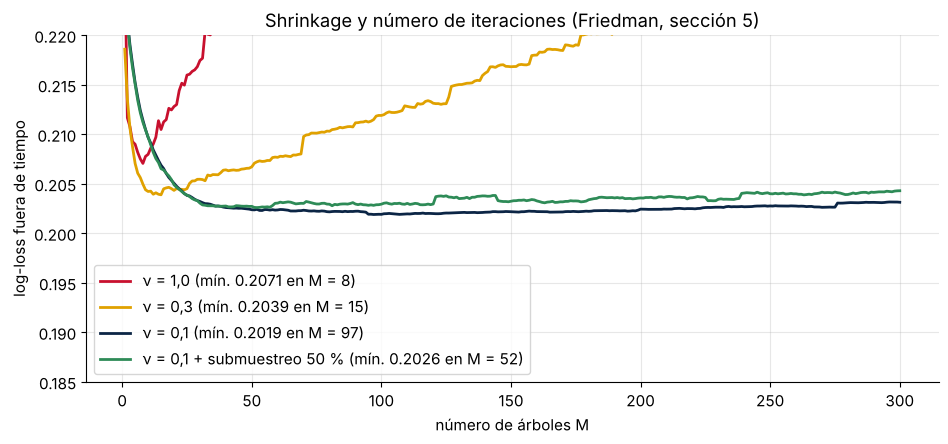

In [4]:
resultados = {}
for nombre, kw in [("ν = 1,0", dict(nu=1.0)), ("ν = 0,3", dict(nu=0.3)), ("ν = 0,1", dict(nu=0.1)), ("ν = 0,1 + submuestreo 50 %", dict(nu=0.1, subsample=0.5))]:
    _, _, h = l2_treeboost(X, y, M=300, J=8, X_eval=Xo, **kw)
    resultados[nombre] = [log_loss(yo, proba(Fm)) for Fm in h]
fig, ax = plt.subplots(figsize=(11, 4.5))
for (nombre, ll), c in zip(resultados.items(), [ROJO, ORO, AZUL, VERDE]):
    ax.plot(np.arange(1, len(ll) + 1), ll, color=c, lw=2, label=f"{nombre} (mín. {min(ll):.4f} en M = {int(np.argmin(ll)) + 1})")
ax.set_xlabel("número de árboles M"); ax.set_ylabel("log-loss fuera de tiempo"); ax.set_ylim(0.185, 0.22); ax.legend(); ax.set_title("Shrinkage y número de iteraciones (Friedman, sección 5)"); plt.show()

**Lectura:** con $\nu = 1$ el modelo alcanza su mejor punto en pocas iteraciones y luego **sobreajusta** rápidamente. Con $\nu$ pequeño la curva es más plana y el mínimo es más bajo: el patrón que reporta Friedman. Por eso en la práctica se fija un $\nu$ pequeño y se elige $M$ con **early stopping** en una muestra de validación (sesión 4).

## 5. Interpretación: influencia relativa y dependencia parcial (sección 8)
- **Influencia relativa** (ecuaciones 43-44): para la variable $x_j$, $\hat I_j^2 = \frac{1}{M}\sum_m \sum_{t} \hat i_t^2 \,\mathbb{1}(v_t = j)$, la mejora de la pérdida en las particiones que usan $x_j$, promediada sobre los árboles.
- **Dependencia parcial** (sección 8.2): $\bar F_S(x_S) = \frac{1}{n}\sum_i F(x_S, x_{i,C})$, el efecto promedio de $x_S$ integrando sobre las demás variables. Friedman la propone precisamente para "abrir" el modelo; es la base del PDP que veremos en el Módulo 7.

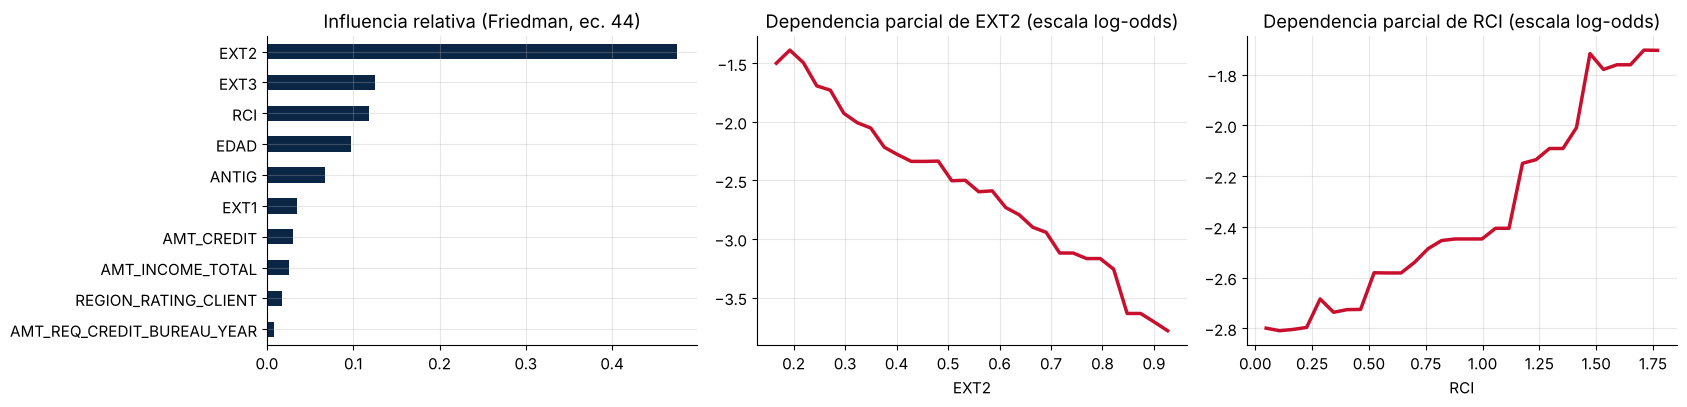

In [5]:
imp = pd.Series(sk.feature_importances_, index=FEATS).sort_values()
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
imp.plot(kind="barh", ax=ax[0], color=AZUL); ax[0].set_title("Influencia relativa (Friedman, ec. 44)")
for a, var in zip(ax[1:], ["EXT2", "RCI"]):
    j = FEATS.index(var)
    grid = np.linspace(np.percentile(X[X[:, j] >= 0, j], 1), np.percentile(X[:, j], 99), 30)
    muestra = X[np.random.default_rng(0).choice(len(X), 3000, replace=False)].copy()
    pdv = []
    for g in grid:
        muestra[:, j] = g; pdv.append(sk.decision_function(muestra).mean())
    a.plot(grid, pdv, color=ROJO, lw=2.5); a.set_title(f"Dependencia parcial de {var} (escala log-odds)"); a.set_xlabel(var)
plt.tight_layout(); plt.show()

**Lectura:** la dependencia parcial de `RCI` muestra el patrón que el logit empírico sugería en el Módulo 3 (plana y luego creciente), **sin especificarlo**: el boosting descubre la forma de la relación. El costo es que el modelo ya no es una tabla de puntos: se necesitan herramientas de interpretación (Módulo 7).

## 6. Ejercicios
1. Implementa **LS_Boost** (regresión con pérdida cuadrática) para predecir `log(AMT_INCOME_TOTAL)` y compáralo con `GradientBoostingRegressor`.
2. Cambia $J$ (hojas por árbol) a 2 (tocones, modelo aditivo puro) y a 32. ¿Cómo cambia el log-loss óptimo? (Friedman, sección 7: $J$ controla el orden de las interacciones.)
3. Agrega *influence trimming* (sección 4.5): omite los casos con $|\tilde y|(2 - |\tilde y|)$ muy pequeño al ajustar cada árbol. ¿Cambia el resultado? ¿Y el tiempo?
4. ¿Qué pasa con la calibración (PD media vs. tasa observada) cuando $M$ es muy grande con $\nu = 1$?